# Proyecto Big Data – Entrega 1 · Workstream 3 (Odei)
## MapReduce, reto de escalado, 5V, arquitectura, README e informe

**Dataset:** Airline On-Time Performance.
- **Tabla principal (vuelos):** un CSV por año en la carpeta `data/` del repositorio (`AAAA.csv`; no se sube a GitHub). El notebook **detecta automáticamente todos los años** que haya en la carpeta: funciona igual con 3 años que con los 22 (1987–2008).
- **Tabla auxiliar (aeropuertos):** `airports.csv` → unión `Origin` / `Dest` = `airports.iata`.

**Qué cubre este notebook (solo la parte del integrante 3):**

| Bloque | Contenido | Tema del curso |
|---|---|---|
| A (parte) | 5V medidas sobre nuestros datos · Data Lake vs. Data Warehouse · Lambda vs. Kappa · diagrama | Temas 1 y 5 |
| C | Hadoop Streaming en Python (map → shuffle → reduce) · mismo cálculo con RDD · comparación | Temas 2, 3 y 4 |
| F | Reto: experimento de escalado (más cores, más datos) | Temas 4 y 5 |
| README / informe | Sección del README y checklist de evidencias | — |

**Cómo usarlo**
1. Ejecuta las celdas **en orden** desde Jupyter.
2. Los bloques marcados con **🖥️ Terminal** se copian en la terminal **desde la carpeta del repositorio** (donde está `docker-compose.yml`). El clúster se arranca con `git pull` y `docker compose up -d`; el token de Jupyter sale con `docker compose logs jupyter`.
3. Todas las evidencias se guardan en `work/evidence/miembro3/`.

> **Regla de tiempos del plan:** cada pareja que se compara (Streaming vs. RDD, 1 vs. 2 vs. 4 cores) se ejecuta **en el mismo portátil, una detrás de otra y sin nada más pesado abierto**.

---
# 0. Preparación

### 0.1 Configuración (no hardcodeada)
Como en el Tema 5 (*Config, not hardcoded*): todas las rutas y parámetros están en un único diccionario. Si el fichero de configuración del pipeline (Carlos) usa otras rutas, **solo se cambia esta celda**.

In [1]:
import os, re, json, time, glob, inspect, statistics, platform
from pathlib import Path
import pandas as pd

import yaml
CFG = yaml.safe_load(open("/home/jovyan/work/config/pipeline.yaml"))   # rutas y parámetros: config/pipeline.yaml
CONFIG = {
    "hdfs":         CFG["hdfs"]["url"],
    "spark_master": CFG["spark"]["master"],          # plan B si no hay workers: "local[4]"
    "local_data":   "/home/jovyan/work/" + CFG["data"]["local_dir"],   # en el portátil: carpeta data/ del repo
    "raw_flights":  CFG["zones"]["raw_flights"],     # zona raw: los CSV tal cual
    "raw_lookup":   CFG["zones"]["raw_lookup"],      # zona raw: airports.csv
    "curated":      CFG["zones"]["curated"],         # zona curated: Parquet particionado por Year
    "results":      CFG["zones"]["results"],         # zona results: resultados pequeños
    "replication":  CFG["hdfs"]["replication"],      # = nº de DataNodes
    "datanodes":    ["datanode1", "datanode2"],      # nombres de los contenedores DataNode
    "namenode_container": "proyecto-bigdata-namenode-1",   # nombre que le da docker compose
}

HDFS = CONFIG["hdfs"]
RAW_FLIGHTS, RAW_LOOKUP = CONFIG["raw_flights"], CONFIG["raw_lookup"]
CURATED, RESULTS = CONFIG["curated"], CONFIG["results"]
NN = CONFIG["namenode_container"]

WORK = Path("/home/jovyan/work")
LOCAL_DATA = Path(CONFIG["local_data"])
MR_DIR = WORK / "mapreduce"
EVIDENCE = WORK / "evidence" / "miembro3"
for d in (MR_DIR, EVIDENCE):
    d.mkdir(parents=True, exist_ok=True)

# Esquemas declarados, no inferidos (Tema 4/5): sin pasada extra sobre los datos
FLIGHTS_SCHEMA = """Year INT, Month INT, DayofMonth INT, DayOfWeek INT, DepTime INT, CRSDepTime INT,
    ArrTime INT, CRSArrTime INT, UniqueCarrier STRING, FlightNum INT, TailNum STRING,
    ActualElapsedTime INT, CRSElapsedTime INT, AirTime INT, ArrDelay INT, DepDelay INT,
    Origin STRING, Dest STRING, Distance INT, TaxiIn INT, TaxiOut INT, Cancelled INT,
    CancellationCode STRING, Diverted INT, CarrierDelay INT, WeatherDelay INT, NASDelay INT,
    SecurityDelay INT, LateAircraftDelay INT"""
AIRPORTS_SCHEMA = "iata STRING, airport STRING, city STRING, state STRING, country STRING, lat DOUBLE, long DOUBLE"

def save_json(obj, name):
    (EVIDENCE / name).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str))
    print("Evidencia guardada:", EVIDENCE / name)

# Años disponibles = ficheros AAAA.csv de la carpeta local
ANIOS = sorted(int(p.stem) for p in LOCAL_DATA.glob("*.csv") if re.fullmatch(r"\d{4}", p.stem))
print(f"Años en {LOCAL_DATA}: {ANIOS}")
print("airports.csv presente:", (LOCAL_DATA / "airports.csv").exists())

Años en /home/jovyan/work/data: [1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008]
airports.csv presente: True


### 0.2 Antes de arrancar Spark: ¿Jupyter ve el clúster?
Si algo de la red falla, crear la sesión o escribir en HDFS **se queda colgado sin dar error** (Tema 5: *"Hangs while writing: Spark reaches the NameNode but not the DataNodes"*). Esta celda lo comprueba en unos segundos, antes de arrancar nada:
- que los nombres `namenode`, `datanode1`, `datanode2` y `spark-master` se resuelven y sus puertos responden;
- que el Spark Master tiene **workers vivos** y **cores libres**. En modo standalone, una aplicación coge por defecto **todos** los cores: si otro notebook (o un intento anterior interrumpido) tiene una SparkSession abierta, la nuestra se queda esperando para siempre.

In [2]:
import socket, urllib.request

def comprobar(host, port, timeout=3):
    try:
        with socket.create_connection((host, port), timeout=timeout):
            return "OK"
    except socket.gaierror:
        return "✘ el nombre no se resuelve → Jupyter no está en la red del clúster"
    except OSError as e:
        return f"✘ no responde ({e.__class__.__name__}) → ¿está el contenedor arrancado? (docker ps)"

master_host = CONFIG["spark_master"].replace("spark://", "").split(":")[0]
red = [("NameNode (HDFS)", "namenode", 9000)] + \
      [(f"DataNode {d}", d, 9866) for d in CONFIG["datanodes"]] + \
      [("Spark Master", master_host, 7077)]
for nombre, host, port in red:
    print(f"{nombre:22s} {host}:{port:<6} {comprobar(host, port)}")

try:
    estado = json.load(urllib.request.urlopen(f"http://{master_host}:8080/json/", timeout=5))
    libres = estado["cores"] - estado["coresused"]
    print(f"\nSpark Master: {estado['aliveworkers']} workers vivos · {estado['cores']} cores · {libres} libres · "
          f"memoria libre {(estado['memory'] - estado['memoryused']) // 1024} GB")
    for app in estado["activeapps"]:
        print(f"  App abierta: {app['name']} ({app['state']}, {app['cores']} cores, id {app['id']})")
    if estado["aliveworkers"] == 0:
        print("✘ No hay workers registrados: la sesión se quedaría esperando para siempre. En la terminal "
              "(carpeta del docker-compose.yml):\n"
              "    docker compose ps -a\n"
              "    docker compose logs spark-worker1 --tail 30\n"
              "    docker compose up -d spark-worker1 spark-worker2\n"
              "  y recarga http://localhost:8080 hasta ver 'Workers: 2 Alive'.")
    elif libres == 0:
        print("✘ No quedan cores libres: cierra las otras SparkSession (spark.stop() o apaga sus kernels "
              "en la pestaña Running de Jupyter) o la nuestra esperará para siempre")
except Exception as e:
    print("✘ No se pudo leer el estado del Spark Master:", e)

NameNode (HDFS)        namenode:9000   OK
DataNode datanode1     datanode1:9866   OK
DataNode datanode2     datanode2:9866   OK
Spark Master           spark-master:7077   OK



Spark Master: 2 workers vivos · 4 cores · 4 libres · memoria libre 4 GB


### 0.3 Sesión de Spark + smoke test
Igual que en el Tema 5 (pasos 4 y 5): `HADOOP_USER_NAME` **antes** de crear la sesión. El smoke test va en dos partes para saber **dónde** falla:
1. un cálculo sin HDFS (`spark.range(1000).count()`): prueba que hay executors;
2. escribir y leer en HDFS: prueba que llegamos al NameNode **y** a los DataNodes.

> Si interrumpes esta celda o falla, haz **Kernel → Restart** antes de repetirla: una sesión a medio crear se queda ocupando cores.
>
> Errores típicos (Tema 5): `UnknownHostException` → Jupyter no ve la red del clúster · `Connection refused` → el clúster aún no está arriba · se cuelga escribiendo → no llega a los DataNodes · `Permission denied` → `HADOOP_USER_NAME` se puso tarde.

In [3]:
os.environ["HADOOP_USER_NAME"] = "root"
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder
         .master(CONFIG["spark_master"])
         .appName("miembro3-mapreduce-reto")
         .getOrCreate())
sc = spark.sparkContext
sc._jsc.hadoopConfiguration().set("dfs.replication", str(CONFIG["replication"]))  # copias de lo que escribamos

# Esperar a que el clúster nos asigne executors. Sin esto, si no hay recursos, la primera acción se cuelga.
if sc.master.startswith("spark://"):
    for _ in range(60):
        n_exec = sc._jsc.sc().getExecutorMemoryStatus().size() - 1        # -1: no contar el driver
        if n_exec > 0:
            break
        time.sleep(1)
    if n_exec == 0:
        raise RuntimeError("En 60 s el clúster no ha dado ningún executor. Mira http://localhost:8080: "
                           "si la app está WAITING, otra SparkSession tiene todos los cores (ver celda 0.2). "
                           "Después: Kernel → Restart.")
    print("Executors:", n_exec)

# Smoke test 1: Spark sin HDFS
assert spark.range(1000).count() == 1000
print("1/2 Spark OK")

# Smoke test 2: HDFS (Tema 5, paso 5)
spark.range(5).write.mode("overwrite").parquet(f"{HDFS}/tmp/smoke_m3")
assert spark.read.parquet(f"{HDFS}/tmp/smoke_m3").count() == 5
print("2/2 HDFS OK · Spark", spark.version, "· master:", sc.master, "· cores:", sc.defaultParallelism)

Executors: 2


1/2 Spark OK


2/2 HDFS OK · Spark 4.2.0 · master: spark://spark-master:7077 · cores: 4


In [4]:
# Utilidades HDFS desde Python. Spark es un cliente de HDFS (Tema 5), igual que 'hdfs dfs':
# usamos su cliente para listar, medir y borrar sin salir del notebook.
def _fs():
    jvm = spark._jvm
    return jvm.org.apache.hadoop.fs.FileSystem.get(jvm.java.net.URI(HDFS), sc._jsc.hadoopConfiguration())

def _p(path):
    return spark._jvm.org.apache.hadoop.fs.Path(HDFS + path)

def hdfs_exists(path): return _fs().exists(_p(path))
def hdfs_size(path):   return _fs().getContentSummary(_p(path)).getLength()     # como 'hdfs dfs -du -s'
def hdfs_ls(path):                                                             # como 'hdfs dfs -ls'
    return [{"fichero": s.getPath().getName(), "bytes": s.getLen(),
             "replicacion": s.getReplication(), "bloque_MB": s.getBlockSize() // 1024**2}
            for s in _fs().listStatus(_p(path))]

In [5]:
# 0.4 Especificaciones de la máquina: van junto a cada tiempo en el informe
with open("/proc/meminfo") as fh:
    mem_gb = round(int(fh.readline().split()[1]) / 1024**2, 1)

entorno = {
    "fecha": time.strftime("%Y-%m-%d %H:%M"),
    "cores_visibles": os.cpu_count(),
    "RAM_visible_GB (≈ RAM asignada a Docker)": mem_gb,
    "spark": spark.version, "python": platform.python_version(),
    "cores_del_cluster_spark": sc.defaultParallelism,
    "anios_dataset": ANIOS,
    "cpu": next((l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")), "?"),
    "maquina": "portátil de referencia del equipo (Docker Desktop); todas las comparativas de tiempos se miden aquí",
}
save_json(entorno, "entorno.json")
entorno

Evidencia guardada: /home/jovyan/work/evidence/miembro3/entorno.json


{'fecha': '2026-10-20 20:59',
 'cores_visibles': 16,
 'RAM_visible_GB (≈ RAM asignada a Docker)': 7.6,
 'spark': '4.2.0',
 'python': '3.13.15',
 'cores_del_cluster_spark': 4,
 'anios_dataset': [1987,
  1988,
  1989,
  1990,
  1991,
  1992,
  1993,
  1994,
  1995,
  1996,
  1997,
  1998,
  1999,
  2000,
  2001,
  2002,
  2003,
  2004,
  2005,
  2006,
  2007,
  2008],
 'cpu': '13th Gen Intel(R) Core(TM) i7-13620H',
 'maquina': 'portátil de referencia del equipo (Docker Desktop); todas las comparativas de tiempos se miden aquí'}

---
# 1. Ingesta: portátil → zona *raw* de HDFS

Como en el Lab del Tema 5 (paso 1), `hdfs dfs -put` sube los ficheros desde el disco del contenedor del NameNode a HDFS, donde se **dividen en bloques de 128 MB y se replican** en los DataNodes. En el lab hacía falta un `docker cp` previo; aquí no: el compose monta la carpeta `data/` del repositorio dentro del NameNode como `/data` (solo lectura), así que el `-put` lee directamente de ahí y **no se duplica el dataset en el disco**.

La zona *raw* guarda los datos **tal como llegan** (Tema 5: *Without raw, every mistake is permanent*).

La celda siguiente **imprime los comandos ya adaptados** a vuestros años y al nombre de vuestro contenedor.

In [6]:
rep = CONFIG["replication"]
total_gb = sum(p.stat().st_size for p in LOCAL_DATA.glob("*.csv")) / 1024**3
print(f"Datos en data/: {total_gb:.1f} GB → HDFS necesita ≈ {total_gb * rep:.1f} GB libres (× replicación {rep}) + margen\n")
print(f"""# 🖥️ Terminal – desde la carpeta del repositorio

# 0) ¿Cabe? 'DFS Remaining' de cada DataNode
docker exec {NN} hdfs dfsadmin -report | grep -E "^Name|DFS Remaining"

# 1) Subir desde /data (= data/ del repo); una línea por año, y una línea "put:" solo si falla
docker exec {NN} hdfs dfs -mkdir -p {RAW_FLIGHTS} {RAW_LOOKUP}
docker exec {NN} bash -c 'for f in /data/[0-9][0-9][0-9][0-9].csv; do echo "== $f"; hdfs dfs -D dfs.replication={rep} -put -f "$f" {RAW_FLIGHTS}/ 2>&1 | grep -E "^put:"; done'
docker exec {NN} hdfs dfs -D dfs.replication={rep} -put -f /data/airports.csv {RAW_LOOKUP}/

# 2) Comprobar
docker exec {NN} hdfs dfs -ls {RAW_FLIGHTS}
docker exec {NN} hdfs dfs -du -s -h {RAW_FLIGHTS} {RAW_LOOKUP}
""")

Datos en data/: 10.8 GB → HDFS necesita ≈ 21.6 GB libres (× replicación 2) + margen

# 🖥️ Terminal – desde la carpeta del repositorio

# 0) ¿Cabe? 'DFS Remaining' de cada DataNode
docker exec proyecto-bigdata-namenode-1 hdfs dfsadmin -report | grep -E "^Name|DFS Remaining"

# 1) Subir desde /data (= data/ del repo); una línea por año, y una línea "put:" solo si falla
docker exec proyecto-bigdata-namenode-1 hdfs dfs -mkdir -p /airline/raw/flights /airline/raw/lookup
docker exec proyecto-bigdata-namenode-1 bash -c 'for f in /data/[0-9][0-9][0-9][0-9].csv; do echo "== $f"; hdfs dfs -D dfs.replication=2 -put -f "$f" /airline/raw/flights/ 2>&1 | grep -E "^put:"; done'
docker exec proyecto-bigdata-namenode-1 hdfs dfs -D dfs.replication=2 -put -f /data/airports.csv /airline/raw/lookup/

# 2) Comprobar
docker exec proyecto-bigdata-namenode-1 hdfs dfs -ls /airline/raw/flights
docker exec proyecto-bigdata-namenode-1 hdfs dfs -du -s -h /airline/raw/flights /airline/raw/lookup



**Explicación de cada comando**
- `hdfs dfsadmin -report`: espacio libre en cada DataNode. Si no cabe, baja `replication` a 1 en `CONFIG` (fallback del plan).
- `/data/…`: es la carpeta `data/` del repositorio vista desde dentro del NameNode (volumen `./data:/data:ro` del compose). No hace falta `docker cp`.
- `-mkdir -p`: crea las carpetas de la zona raw (sin error si ya existen).
- `-put -f`: `/data` → HDFS. `[0-9][0-9][0-9][0-9].csv` coge **todos los años** que haya, sean los que sean. `-f` sobrescribe: si se relanza, el resultado es el mismo (**idempotente**, Tema 5) y no se duplican ficheros.
- `-D dfs.replication=…`: nº de copias de cada bloque solo para esta subida (como `-D dfs.blocksize` en el lab del Tema 3).
- `-du -s -h`: 1ª columna = tamaño de los datos; 2ª = espacio real ocupado con réplicas (× replicación).
- `2>&1 | grep -E "^put:"`: oculta los avisos de Hadoop y deja solo los errores. Si sale un `put:` con *safe mode* o *0 of the 1 minReplication nodes*, casi siempre es falta de disco en Docker.

In [7]:
# 1.1 Comprobar que TODOS los años locales están en HDFS (Fail loudly, Tema 5)
en_hdfs = pd.DataFrame(hdfs_ls(RAW_FLIGHTS))
en_hdfs["Year"] = en_hdfs.fichero.str.extract(r"^(\d{4})\.csv").astype(float)
anios_hdfs = sorted(en_hdfs.Year.dropna().astype(int))
faltan = sorted(set(ANIOS) - set(anios_hdfs))
assert not faltan, f"Faltan en HDFS los años: {faltan}. Repite el -put."
assert hdfs_exists(RAW_LOOKUP + "/airports.csv"), "Falta airports.csv en HDFS"

# Un -put que falla a medias (p. ej. disco lleno) puede dejar ficheros CORTADOS: comparamos tamaños con los locales
tam_local = {int(p.stem): p.stat().st_size for p in LOCAL_DATA.glob("*.csv") if re.fullmatch(r"\d{4}", p.stem)}
en_hdfs["bytes_local"] = en_hdfs.Year.map(tam_local)
incompletos = en_hdfs[en_hdfs.Year.notna() & (en_hdfs.bytes != en_hdfs.bytes_local)]
assert incompletos.empty, ("Ficheros con tamaño distinto al local (subida incompleta). Bórralos con "
                           "'hdfs dfs -rm' y repite el -put:\n" + incompletos[["fichero", "bytes", "bytes_local"]].to_string())
assert hdfs_size(RAW_LOOKUP + "/airports.csv") == (LOCAL_DATA / "airports.csv").stat().st_size, "airports.csv incompleto"

ANIOS = anios_hdfs                     # a partir de aquí manda lo que hay en HDFS
SAMPLE_YEAR = ANIOS[0]                 # año pequeño para pruebas rápidas
SAMPLE_FILE = f"{RAW_FLIGHTS}/{SAMPLE_YEAR}.csv"
print(f"{len(ANIOS)} años en HDFS ({ANIOS[0]}–{ANIOS[-1]}) · año de prueba: {SAMPLE_YEAR}")
save_json({"anios": ANIOS, "ficheros": en_hdfs.to_dict("records")}, "ingesta_raw.json")
en_hdfs

22 años en HDFS (1987–2008) · año de prueba: 1987
Evidencia guardada: /home/jovyan/work/evidence/miembro3/ingesta_raw.json


,fichero,bytes,replicacion,bloque_MB,Year,bytes_local
0,1987.csv,127162942,2,128,1987.0,127162942
1,1988.csv,501039472,2,128,1988.0,501039472
2,1989.csv,486518821,2,128,1989.0,486518821
3,1990.csv,509194687,2,128,1990.0,509194687
4,1991.csv,491210093,2,128,1991.0,491210093
5,1992.csv,492313731,2,128,1992.0,492313731
6,1993.csv,490753652,2,128,1993.0,490753652
7,1994.csv,501558665,2,128,1994.0,501558665
8,1995.csv,530751568,2,128,1995.0,530751568
9,1996.csv,533922363,2,128,1996.0,533922363


---
# 2. Bloque A – Las 5V, medidas sobre nuestros datos

No basta con decir "es Big Data": medimos cada V. Leemos la zona raw con el **esquema explícito** y en modo `PERMISSIVE` (Tema 5): los valores que no encajan en el tipo se convierten en `null` **sin avisar**, así que los contamos para saber cuánta "suciedad" hay.

> `encoding = ISO-8859-1`: algunos años no están en UTF-8. Con latin-1 la lectura nunca falla.

In [8]:
raw = (spark.read.schema(FLIGHTS_SCHEMA)
       .option("header", True)
       .option("nullValue", "NA")            # en estos CSV los vacíos vienen como "NA"
       .option("mode", "PERMISSIVE")
       .option("encoding", "ISO-8859-1")
       .csv(f"{HDFS}{RAW_FLIGHTS}"))          # lee la carpeta entera = todos los años
airports = (spark.read.schema(AIRPORTS_SCHEMA).option("header", True)
            .csv(f"{HDFS}{RAW_LOOKUP}/airports.csv"))
raw.show(3)

+----+-----+----------+---------+-------+----------+-------+----------+-------------+---------+-------+-----------------+--------------+-------+--------+--------+------+----+--------+------+-------+---------+----------------+--------+------------+------------+--------+-------------+-----------------+
|Year|Month|DayofMonth|DayOfWeek|DepTime|CRSDepTime|ArrTime|CRSArrTime|UniqueCarrier|FlightNum|TailNum|ActualElapsedTime|CRSElapsedTime|AirTime|ArrDelay|DepDelay|Origin|Dest|Distance|TaxiIn|TaxiOut|Cancelled|CancellationCode|Diverted|CarrierDelay|WeatherDelay|NASDelay|SecurityDelay|LateAircraftDelay|
+----+-----+----------+---------+-------+----------+-------+----------+-------------+---------+-------+-----------------+--------------+-------+--------+--------+------+----+--------+------+-------+---------+----------------+--------+------------+------------+--------+-------------+-----------------+
|1988|    1|         9|        6|   1348|      1331|   1458|      1435|           PI|      942

In [9]:
# 2.1 VOLUMEN: tamaño, bloques y filas (por año y total)
fich = en_hdfs.dropna(subset=["Year"])
filas_anio = raw.groupBy("Year").count().orderBy("Year").toPandas()
tabla_anios = fich.assign(Year=fich.Year.astype(int)).merge(filas_anio, on="Year")
tabla_anios["MB"] = (tabla_anios.bytes / 1024**2).round(0)
tabla_anios["bloques_128MB"] = -(-tabla_anios.bytes // (128 * 1024**2))     # redondeo hacia arriba
tabla_anios.to_csv(EVIDENCE / "5v_volumen_por_anio.csv", index=False)

volumen = {
    "anios": len(ANIOS),
    "raw_GB": round(tabla_anios.bytes.sum() / 1024**3, 2),
    "raw_GB_con_replicas": round(hdfs_size(RAW_FLIGHTS) * CONFIG["replication"] / 1024**3, 2),
    "bloques_HDFS": int(tabla_anios.bloques_128MB.sum()),
    "filas": int(tabla_anios["count"].sum()),
    "MB_medios_por_anio": round(tabla_anios.MB.mean()),
}
save_json(volumen, "5v_volumen.json")
display(tabla_anios[["Year", "MB", "bloques_128MB", "count"]])
volumen

Evidencia guardada: /home/jovyan/work/evidence/miembro3/5v_volumen.json


,Year,MB,bloques_128MB,count
0,1987,121.0,1,1311826
1,1988,478.0,4,5202096
2,1989,464.0,4,5041200
3,1990,486.0,4,5270893
4,1991,468.0,4,5076925
5,1992,470.0,4,5092157
6,1993,468.0,4,5070501
7,1994,478.0,4,5180048
8,1995,506.0,4,5327435
9,1996,509.0,4,5351983


{'anios': 22,
 'raw_GB': np.float64(10.78),
 'raw_GB_con_replicas': 21.56,
 'bloques_HDFS': 95,
 'filas': 118914458,
 'MB_medios_por_anio': 502}

In [10]:
# 2.2 VERACIDAD: una única pasada que cuenta los problemas de calidad
def pct(cond):
    return F.round(100 * F.avg(F.when(cond, 1).otherwise(0)), 3)

operado = (F.col("Cancelled") == 0) & (F.col("Diverted") == 0)
hora_imposible = lambda c: (F.col(c) > 2400) | ((F.col(c) % 100) >= 60)     # formato hhmm

veracidad = raw.agg(
    pct(F.col("Cancelled") == 1).alias("pct_cancelados"),
    pct(F.col("Diverted") == 1).alias("pct_desviados"),
    pct(operado & F.col("ArrDelay").isNull()).alias("pct_operados_sin_ArrDelay"),
    pct(hora_imposible("DepTime")).alias("pct_DepTime_imposible"),
    pct(hora_imposible("CRSDepTime")).alias("pct_CRSDepTime_imposible"),
    pct((F.col("ArrDelay") < -120) | (F.col("ArrDelay") > 1440)).alias("pct_ArrDelay_extremo"),
    pct(F.col("Distance").isNull() | (F.col("Distance") <= 0)).alias("pct_Distance_invalida"),
    pct(F.col("TailNum").isNull()).alias("pct_TailNum_null"),
    pct(F.col("ArrDelay") > 15).alias("pct_target_ArrDelay_mayor_15"),
    F.min("ArrDelay").alias("ArrDelay_min"), F.max("ArrDelay").alias("ArrDelay_max"),
).first().asDict()

# Regla "fila útil para analizar retrasos" con el patrón del Tema 5 (coalesce: True AND null = null)
regla = operado & F.col("ArrDelay").isNotNull() & F.col("Origin").isNotNull() & F.col("Dest").isNotNull()
ok = F.coalesce(regla, F.lit(False))
n_in, n_ok = volumen["filas"], raw.filter(ok).count()
n_bad = raw.filter(~ok).count()
assert n_ok + n_bad == n_in, "se pierden filas: revisa los null de la regla"
veracidad.update({"filas_utiles": n_ok, "filas_descartables": n_bad, "pct_descartables": round(100 * n_bad / n_in, 2)})
veracidad

{'pct_cancelados': 1.876,
 'pct_desviados': 0.229,
 'pct_operados_sin_ArrDelay': 0.0,
 'pct_DepTime_imposible': 0.003,
 'pct_CRSDepTime_imposible': 0.0,
 'pct_ArrDelay_extremo': 0.0,
 'pct_Distance_invalida': 0.17,
 'pct_TailNum_null': 31.405,
 'pct_target_ArrDelay_mayor_15': 18.903,
 'ArrDelay_min': -1437,
 'ArrDelay_max': 2598,
 'filas_utiles': 116411532,
 'filas_descartables': 2502926,
 'pct_descartables': 2.1}

In [11]:
# 2.3 Duplicados por clave lógica de vuelo (shuffle de todo el dataset: tarda unos minutos)
clave = ["Year", "Month", "DayofMonth", "UniqueCarrier", "FlightNum", "Origin", "Dest", "CRSDepTime"]
dup = (raw.groupBy(clave).count().filter("count > 1")
          .agg(F.count("*").alias("claves_duplicadas"), F.sum(F.col("count") - 1).alias("filas_sobrantes"))
          .first().asDict())
veracidad.update({k: int(v or 0) for k, v in dup.items()})
save_json(veracidad, "5v_veracidad.json")
dup

Evidencia guardada: /home/jovyan/work/evidence/miembro3/5v_veracidad.json


{'claves_duplicadas': 1084, 'filas_sobrantes': 1091}

In [12]:
# 2.4 VARIEDAD: el esquema cambia con los años + cobertura de la tabla auxiliar airports
evol = (raw.groupBy("Year").agg(
            F.round(100 * F.avg(F.col("CarrierDelay").isNotNull().cast("int")), 1).alias("pct_con_CarrierDelay"),
            F.round(100 * F.avg(F.col("TailNum").isNotNull().cast("int")), 1).alias("pct_con_TailNum"),
            F.countDistinct("UniqueCarrier").alias("aerolineas"),
            F.countDistinct("Origin").alias("aeropuertos_origen"))
        .orderBy("Year").toPandas())
evol.to_csv(EVIDENCE / "5v_esquema_por_anio.csv", index=False)

codigos = raw.select(F.col("Origin").alias("iata")).union(raw.select(F.col("Dest").alias("iata"))).distinct()
sin_match = codigos.join(airports, "iata", "left_anti").toPandas().iata.dropna().tolist()
vuelos_con_aeropuerto = raw.join(F.broadcast(airports.select(F.col("iata").alias("Origin"))), "Origin", "left_semi").count()

variedad = {
    "aeropuertos_en_airports_csv": airports.count(),
    "aeropuertos_distintos_en_vuelos": codigos.count(),
    "codigos_sin_match_en_airports": sorted(sin_match),
    "pct_vuelos_con_Origin_en_airports": round(100 * vuelos_con_aeropuerto / n_in, 4),
    "anios_con_CarrierDelay": evol.loc[evol.pct_con_CarrierDelay > 0, "Year"].tolist(),
}
save_json(variedad, "5v_variedad.json")
display(evol)
variedad

Evidencia guardada: /home/jovyan/work/evidence/miembro3/5v_variedad.json


,Year,pct_con_CarrierDelay,pct_con_TailNum,aerolineas,aeropuertos_origen
0,1987,0.0,0.0,14,237
1,1988,0.0,0.0,14,238
2,1989,0.0,0.0,13,237
3,1990,0.0,0.0,12,235
4,1991,0.0,0.0,12,233
5,1992,0.0,0.0,10,233
6,1993,0.0,0.0,10,227
7,1994,0.0,0.0,10,224
8,1995,0.0,100.0,10,218
9,1996,0.0,100.0,10,211


{'aeropuertos_en_airports_csv': 3376,
 'aeropuertos_distintos_en_vuelos': 351,
 'codigos_sin_match_en_airports': ['CBM'],
 'pct_vuelos_con_Origin_en_airports': 100.0,
 'anios_con_CarrierDelay': [2003, 2004, 2005, 2006, 2007, 2008]}

### 2.5 Tabla 5V para el informe
Rellena los `{…}` con los JSON de `evidence/miembro3/5v_*.json`. Somos honestos con las V que **no** aplican.

| V | ¿Aplica? | Evidencia en nuestro dataset | Consecuencia de diseño |
|---|---|---|---|
| **Volumen** | Parcialmente | {raw_GB} GB en {anios} CSV (~{MB_medios_por_anio} MB por año), {filas} filas, {bloques_HDFS} bloques de 128 MB. No es Big Data a escala de empresa, pero no cabe cómodamente en memoria con pandas en un portátil. | HDFS reparte los bloques y Spark procesa por partes; Parquet para leer solo las columnas necesarias; partición por `Year` (≈ un fichero razonable por año). |
| **Velocidad** | **No aplica** | Dataset histórico cerrado: los ficheros anuales llegan una vez y no cambian. | Procesamiento **batch**. Streaming queda como extensión (capa *speed* del diagrama). |
| **Variedad** | Baja | Todo es tabular: vuelos + `airports.csv`. Pero el esquema evoluciona: las causas de retraso solo tienen datos en {anios_con_CarrierDelay}; `TailNum` falta en los años antiguos; {n} códigos de aeropuerto sin match en `airports.csv` ({pct_vuelos_con_Origin_en_airports}% de vuelos sí lo tienen); hay años que no están en UTF-8. | Esquema explícito, columnas opcionales como `null`, `left join` con airports (un `inner` perdería vuelos). |
| **Veracidad** | **Sí, la más importante** | {pct_cancelados}% cancelados, {pct_desviados}% desviados, {pct_operados_sin_ArrDelay}% operados sin `ArrDelay`, horas imposibles {pct_DepTime_imposible}%, retrasos extremos {pct_ArrDelay_extremo}%, {filas_sobrantes} filas duplicadas. En total {pct_descartables}% de filas no sirven para analizar retrasos. | Zona raw intacta + zona curated limpia; checks de calidad en el pipeline; excluir cancelados y desviados. |
| **Valor** | Sí | Saber qué aerolíneas y rutas se retrasan más y predecir el riesgo de retraso antes del vuelo ({pct_target_ArrDelay_mayor_15}% de vuelos con `ArrDelay > 15` → clases desbalanceadas). | Las 3 preguntas analíticas y el baseline de MLlib. |

---
# 3. Bloque A – Arquitectura

### 3.1 Caso de uso hipotético
> **"Delay Insights"** para el equipo de operaciones de una aerolínea:
> 1. Cada mañana, los **analistas** consultan informes históricos: retraso por aerolínea y año, peores rutas de cada aeropuerto, cada aerolínea frente a la media de su aeropuerto.
> 2. Cada semana, los **data scientists** reentrenan un modelo que estima, al programar un vuelo, la probabilidad de llegar con más de 15 min de retraso.
> 3. En el futuro quieren un panel con los retrasos **del día en curso**.

### 3.2 Data Warehouse vs. Data Lake → **Data Lake por zonas**

| Criterio | Data Warehouse | Data Lake | Nuestro caso |
|---|---|---|---|
| Esquema | Se define al escribir (*schema-on-write*) | Se define al leer (*schema-on-read*) | El esquema cambia entre años y hay datos sucios → guardamos el original y decidimos al leer |
| Consumidores | Informes SQL / BI | BI + ML + análisis ad-hoc | Tenemos informes **y** entrenamiento de ML, que necesita cada vuelo, no agregados |
| Reprocesar | Recargar es caro | La zona raw permite reconstruir todo | Si hay un bug en la limpieza, se reconstruye curated desde raw (Tema 5) |
| Infraestructura | Motor que une almacenamiento y cómputo | Almacenamiento (HDFS) y cómputo (Spark) separados | Es exactamente lo que montamos en Docker |

Del warehouse tomamos la idea de datos limpios y tipados en la zona *curated* (Parquet) y tablas pequeñas listas para consultar en *results*: el patrón **raw → curated → results** (bronze / silver / gold, "medallion", Tema 5).

### 3.3 Lambda vs. Kappa → **Lambda, implementando solo la capa batch**

| Criterio | Lambda | Kappa | Nuestro caso |
|---|---|---|---|
| Fuente | Ficheros históricos + eventos | Un único flujo de eventos que se reproduce | Nuestros datos son **ficheros anuales**, no eventos |
| Reprocesar el histórico | Batch sobre todo el histórico | Volver a pasar todo el flujo por streaming | Reprocesar todos los años en batch es simple y barato |
| Tiempo real | Capa *speed* aparte | Todo es streaming | Solo lo necesita el punto 3, y es futuro |
| Complejidad | Dos caminos de código | Uno | Solo construimos la capa batch ahora |

**Decisión:** la capa **batch** (HDFS + Spark + MLlib) cubre los puntos 1 y 2 y es lo que entregamos. La capa **speed** (feed de vuelos del día → Kafka + Spark Structured Streaming) queda diseñada, no implementada: la Velocidad no aplica a nuestro dataset y el curso trabajó solo en batch (Tema 5, *What we didn't cover*).

### 3.4 Diagrama
(JupyterLab ≥ 4.1 dibuja Mermaid; la celda siguiente genera un PNG para el informe.)

```mermaid
flowchart LR
    SRC[Vuelos: un CSV por año<br/>+ airports.csv] -->|hdfs dfs -put desde /data| RAW
    subgraph HDFS["HDFS: NameNode + DataNodes, bloques de 128 MB replicados"]
        RAW[(raw<br/>tal como llega)]
        CUR[(curated<br/>Parquet por Year)]
        RES[(results<br/>tablas pequeñas)]
    end
    RAW -->|Spark: esquema, limpieza, checks| CUR
    RAW -->|Hadoop Streaming + Spark RDD| RES
    CUR -->|Spark SQL + join airports + MLlib| RES
    RES --> USR[Jupyter / informe]
    LIVE[Vuelos del día] -.->|capa speed: futuro| RT[(vista tiempo real)]
    RT -.-> USR
```

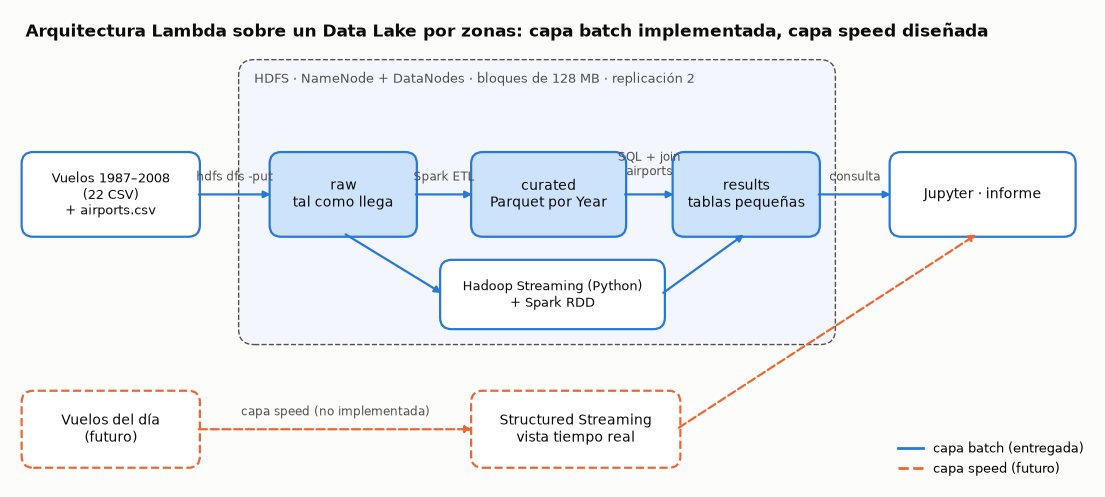

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

INK, MUTED, SURF = "#0b0b0b", "#52514e", "#fcfcfb"
ZONE, BATCH, SPEED = "#cde2fb", "#2a78d6", "#eb6834"

fig, ax = plt.subplots(figsize=(14, 6.2), facecolor=SURF)
ax.set_xlim(0, 14); ax.set_ylim(0, 6.2); ax.axis("off")

def box(x, y, w, h, text, fc="white", ec=BATCH, ls="-", fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                fc=fc, ec=ec, lw=1.6, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=INK)

def arrow(a, b, label="", color=BATCH, ls="-", dy=0.18):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6, ls=ls))
    if label:
        ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2 + dy, label, ha="center", fontsize=8.5, color=MUTED)

ax.add_patch(FancyBboxPatch((3.0, 1.9), 7.6, 3.6, boxstyle="round,pad=0.05,rounding_size=0.2",
                            fc="#f3f7fd", ec=MUTED, lw=1, ls="--"))
ax.text(3.15, 5.25, f"HDFS · NameNode + DataNodes · bloques de 128 MB · replicación {CONFIG['replication']}",
        fontsize=9, color=MUTED)

box(0.2, 3.3, 2.2, 1.0, f"Vuelos {ANIOS[0]}–{ANIOS[-1]}\n({len(ANIOS)} CSV)\n+ airports.csv", fs=9)
box(3.4, 3.3, 1.8, 1.0, "raw\ntal como llega", fc=ZONE)
box(6.0, 3.3, 1.9, 1.0, "curated\nParquet por Year", fc=ZONE)
box(8.6, 3.3, 1.8, 1.0, "results\ntablas pequeñas", fc=ZONE)
box(11.4, 3.3, 2.3, 1.0, "Jupyter · informe")
box(5.6, 2.1, 2.8, 0.8, "Hadoop Streaming (Python)\n+ Spark RDD", fs=9)
box(0.2, 0.3, 2.2, 0.9, "Vuelos del día\n(futuro)", ec=SPEED, ls="--")
box(6.0, 0.3, 2.6, 0.9, "Structured Streaming\nvista tiempo real", ec=SPEED, ls="--")

arrow((2.4, 3.8), (3.4, 3.8), "hdfs dfs -put")
arrow((5.2, 3.8), (6.0, 3.8), "Spark ETL")
arrow((7.9, 3.8), (8.6, 3.8), "SQL + join\nairports", dy=0.25)
arrow((10.4, 3.8), (11.4, 3.8), "consulta")
arrow((4.3, 3.3), (5.6, 2.5))
arrow((8.4, 2.5), (9.5, 3.3))
arrow((2.4, 0.75), (6.0, 0.75), "capa speed (no implementada)", color=SPEED, ls="--")
arrow((8.6, 0.75), (12.5, 3.3), color=SPEED, ls="--")

ax.text(0.2, 5.85, "Arquitectura Lambda sobre un Data Lake por zonas: capa batch implementada, capa speed diseñada",
        fontsize=12, color=INK, weight="bold")
ax.plot([], [], color=BATCH, lw=2, label="capa batch (entregada)")
ax.plot([], [], color=SPEED, lw=2, ls="--", label="capa speed (futuro)")
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.savefig(EVIDENCE / "arquitectura.png", dpi=160, bbox_inches="tight", facecolor=SURF)
plt.show()

---
# 4. Bloque C – MapReduce con Hadoop Streaming

### 4.1 Del Python del Tema 2 a Hadoop
En el Tema 2 escribimos `map_step()` → `shuffle_step()` → `reduce_step()` en un solo programa. Hadoop Streaming hace lo mismo **repartido**: nosotros escribimos solo el *map* y el *reduce* en Python (leen de `stdin` y escriben en `stdout`) y Hadoop se encarga del shuffle (agrupar y ordenar por clave), de leer los bloques de HDFS y de escribir el resultado en HDFS.

### 4.2 Qué calculamos
Para **cada año y aerolínea**: nº de vuelos operados, retraso medio de llegada y % de vuelos con `ArrDelay > 15`. Es como el ejemplo del Tema 2 de *average rating per category*, pero con la categoría `Año|Aerolínea`.
- Coincide con la **pregunta analítica 1**, así que se puede cruzar con el resultado de Spark SQL.
- El % de retrasados es la tasa de la **variable objetivo** del modelo.
- Se excluyen cancelados, desviados y filas con `ArrDelay = NA`.

Columnas del CSV que usamos (posición): `Year` (0), `UniqueCarrier` (8), `ArrDelay` (14), `Cancelled` (21), `Diverted` (23).

> Los scripts no usan *f-strings* porque el contenedor del NameNode (imagen bde2020, Debian 9) trae Python 3.5.

In [14]:
%%writefile /home/jovyan/work/mapreduce/mapper.py
#!/usr/bin/env python3
"""MAP: cada línea del CSV -> 'Año|Aerolínea <TAB> retraso <TAB> 1 <TAB> retrasado(0/1)'."""
import io
import sys

YEAR, CARRIER, ARR_DELAY, CANCELLED, DIVERTED = 0, 8, 14, 21, 23

for line in io.TextIOWrapper(sys.stdin.buffer, encoding="latin-1"):
    f = line.rstrip("\r\n").split(",")
    if len(f) < 24 or not f[YEAR].isdigit():           # cabecera ("Year"), línea rota o año vacío
        continue
    if f[CANCELLED] != "0" or f[DIVERTED] != "0":      # solo vuelos operados
        continue
    try:
        delay = int(float(f[ARR_DELAY]))               # "NA" -> ValueError
    except ValueError:
        continue
    late = 1 if delay > 15 else 0
    sys.stdout.write("{}|{}\t{}\t1\t{}\n".format(f[YEAR], f[CARRIER], delay, late))

Overwriting /home/jovyan/work/mapreduce/mapper.py


In [15]:
%%writefile /home/jovyan/work/mapreduce/combiner.py
#!/usr/bin/env python3
"""COMBINER: suma parcial dentro de cada tarea de map, antes del shuffle.
Entrada y salida con el mismo formato que el mapper."""
import sys

def emit(key, s, n, late):
    sys.stdout.write("{}\t{}\t{}\t{}\n".format(key, s, n, late))

current, s, n, late = None, 0, 0, 0
for line in sys.stdin:
    key, v_sum, v_n, v_late = line.rstrip("\n").split("\t")
    if key != current:                                 # las claves llegan ordenadas
        if current is not None:
            emit(current, s, n, late)
        current, s, n, late = key, 0, 0, 0
    s += int(v_sum); n += int(v_n); late += int(v_late)
if current is not None:
    emit(current, s, n, late)

Overwriting /home/jovyan/work/mapreduce/combiner.py


In [16]:
%%writefile /home/jovyan/work/mapreduce/reducer.py
#!/usr/bin/env python3
"""REDUCE: suma por clave y emite
Año <TAB> Aerolínea <TAB> n_vuelos <TAB> suma_retraso <TAB> retraso_medio <TAB> pct_retrasados"""
import sys

def emit(key, s, n, late):
    year, carrier = key.split("|")
    sys.stdout.write("{}\t{}\t{}\t{}\t{:.4f}\t{:.4f}\n".format(year, carrier, n, s, s / n, 100.0 * late / n))

current, s, n, late = None, 0, 0, 0
for line in sys.stdin:
    key, v_sum, v_n, v_late = line.rstrip("\n").split("\t")
    if key != current:
        if current is not None:
            emit(current, s, n, late)
        current, s, n, late = key, 0, 0, 0
    s += int(v_sum); n += int(v_n); late += int(v_late)
if current is not None:
    emit(current, s, n, late)

Overwriting /home/jovyan/work/mapreduce/reducer.py


**¿Por qué la media se calcula solo en el reducer?** Porque **no se pueden promediar medias parciales**: la media de (10, 20, 30) y de (40) no es la media de 20 y 40. Por eso por el shuffle viajan `(suma, n)`, que sí se pueden ir sumando, y la división se hace al final.

### 4.3 Script de lanzamiento
Dos modos, según el clúster:
- **`yarn`**: el clúster de clase (`docker-hadoop`, Tema 3) tiene ResourceManager y NodeManager. El job aparece en `http://localhost:8088` (RUNNING → SUCCEEDED), igual que el WordCount del lab. Los scripts viajan a las tareas con `-files`.
- **`local`**: el compose del proyecto **no tiene YARN** (para ahorrar RAM). Hadoop ejecuta las tareas en hilos dentro del contenedor del NameNode, **leyendo y escribiendo en HDFS igualmente**. Es una limitación que hay que contar en el informe: el patrón es MapReduce, pero no se reparte entre máquinas.

El script es **idempotente**: borra la carpeta de salida antes de escribir (si no, Hadoop falla con "output directory already exists", igual que `PATH_ALREADY_EXISTS` en Spark).

In [17]:
%%writefile /home/jovyan/work/mapreduce/run_streaming.sh
#!/bin/bash
# Uso: bash run_streaming.sh <entrada_hdfs> <salida_hdfs> [yes|no: combiner] [local|yarn]
set -eo pipefail
INPUT=${1:-/airline/raw/flights}
OUTPUT=${2:-/airline/results/mr_delay_by_carrier_year}
USE_COMBINER=${3:-yes}
MODE=${4:-local}
DIR=/opt/mapreduce
JAR=$(ls "$HADOOP_HOME"/share/hadoop/tools/lib/hadoop-streaming-*.jar | head -1)

hdfs dfs -rm -r -f -skipTrash "$OUTPUT"            # idempotente: relanzar no falla ni duplica

if [ "$MODE" = "yarn" ]; then                       # tareas en el NodeManager: enviamos los scripts
  GENERIC=(-D mapreduce.framework.name=yarn -files "$DIR/mapper.py,$DIR/combiner.py,$DIR/reducer.py")
  MAP="python3 mapper.py"; COMB="python3 combiner.py"; RED="python3 reducer.py"
else                                                # sin YARN: 4 hilos de map, como los 4 cores de Spark
  GENERIC=(-D mapreduce.framework.name=local -D mapreduce.local.map.tasks.maximum=4)
  MAP="python3 $DIR/mapper.py"; COMB="python3 $DIR/combiner.py"; RED="python3 $DIR/reducer.py"
fi
COMBINER=()
if [ "$USE_COMBINER" = "yes" ]; then COMBINER=(-combiner "$COMB"); fi

echo "INPUT=$INPUT OUTPUT=$OUTPUT COMBINER=$USE_COMBINER MODE=$MODE"
START=$(date +%s.%N)
hadoop jar "$JAR" "${GENERIC[@]}" \
  -D mapreduce.job.reduces=1 \
  -D mapreduce.job.name="retraso_por_anio_aerolinea" \
  -mapper "$MAP" "${COMBINER[@]}" -reducer "$RED" \
  -input "$INPUT" -output "$OUTPUT"
END=$(date +%s.%N)
echo "ELAPSED_SECONDS=$(awk "BEGIN{print $END - $START}")"
hdfs dfs -cat "$OUTPUT/part-*" | head -5

Overwriting /home/jovyan/work/mapreduce/run_streaming.sh


### 4.4 Prueba local: `cat | map | sort | reduce`
Antes de usar Hadoop comprobamos los scripts en Jupyter con un trozo del año de prueba. Es exactamente el modelo del Tema 2: `sort` hace de shuffle.

In [18]:
sample_local = MR_DIR / "sample.csv"
with open(sample_local, "w", encoding="latin-1") as fh:
    for line in sc.textFile(f"{HDFS}{SAMPLE_FILE}").take(200_000):
        fh.write(line + "\n")
print(sample_local, sample_local.stat().st_size // 1024, "KB")

/home/jovyan/work/mapreduce/sample.csv 18925 KB


In [19]:
%%bash
cd /home/jovyan/work/mapreduce
cat sample.csv | python3 mapper.py | LC_ALL=C sort | python3 reducer.py > local_out.tsv
cat sample.csv | python3 mapper.py | LC_ALL=C sort | python3 combiner.py | LC_ALL=C sort | python3 reducer.py > local_out_comb.tsv
diff -q local_out.tsv local_out_comb.tsv && echo "Mismo resultado con y sin combiner ✔"
echo "líneas de entrada: $(wc -l < sample.csv) · parejas que salen del map: $(python3 mapper.py < sample.csv | wc -l) · claves finales: $(wc -l < local_out.tsv)"
head local_out.tsv

Mismo resultado con y sin combiner ✔


líneas de entrada: 200000 · parejas que salen del map: 198203 · claves finales: 9


1987	EA	14011	71052	5.0712	14.0104
1987	HP	14860	140428	9.4501	21.6487
1987	NW	37107	291469	7.8548	2

0.2442
1987	PA (1)	5078	31658	6.2343	17.4872
1987	PI	15779	104560	6.6265	16.6741
1987	PS	13331	23292

2	17.4722	37.2515
1987	TW	23701	136911	5.7766	18.3621
1987	UA	52626	277052	5.2645	17.5598
1987	WN	21

710	77953	3.5906	13.4270


### 4.5 🖥️ Terminal – ejecutar en Hadoop
La celda siguiente imprime los comandos para vuestro contenedor y vuestro año de prueba.
- **Python en el contenedor:** la imagen bde2020 suele venir sin `python3`. Se instala una vez (se pierde con `docker compose down`; para que sea reproducible, Carlos puede añadirlo al compose con una imagen propia). En modo `yarn` hay que instalarlo **también en el `nodemanager`**, que es donde corren las tareas.
- **Prueba con un año, con y sin combiner**, para medir cuánto reduce el shuffle.
- **Todos los años:** en una ventana de terminal aparte (puede tardar horas). En el mismo portátil donde se ejecute el RDD completo (sección 5).

In [20]:
MODE = "local"     # sin YARN: Hadoop Streaming se ejecuta dentro del NameNode
LOG = "evidence/miembro3"
print(f"""# 🖥️ Terminal – desde la carpeta del repositorio
# El NameNode del compose ya trae python3 y ve mapreduce/ en /opt/mapreduce: no hay que instalar ni copiar nada.
# Justo después de arrancar, HDFS pasa unos segundos en safe mode (no admite escrituras):
docker compose exec namenode hdfs dfsadmin -safemode wait

# 1) Un año ({SAMPLE_YEAR}), con y sin combiner
docker compose exec -T namenode bash -c "bash /opt/mapreduce/run_streaming.sh {SAMPLE_FILE} {RESULTS}/mr_sample_comb yes {MODE} 2>&1" > {LOG}/streaming_sample_comb.log
docker compose exec -T namenode bash -c "bash /opt/mapreduce/run_streaming.sh {SAMPLE_FILE} {RESULTS}/mr_sample_nocomb no {MODE} 2>&1" > {LOG}/streaming_sample_nocomb.log

# 2) Todos los años ({ANIOS[0]}–{ANIOS[-1]}) – sin más trabajos pesados en marcha
docker compose exec -T namenode bash -c "bash /opt/mapreduce/run_streaming.sh {RAW_FLIGHTS} {RESULTS}/mr_delay_by_carrier_year yes {MODE} 2>&1" > {LOG}/streaming_full.log

# En PowerShell: cambiar  > fichero  por  | Out-File -Encoding utf8 fichero
""")


# 🖥️ Terminal – desde la carpeta del repositorio
# El NameNode del compose ya trae python3 y ve mapreduce/ en /opt/mapreduce: no hay que instalar ni copiar nada.
# Justo después de arrancar, HDFS pasa unos segundos en safe mode (no admite escrituras):
docker compose exec namenode hdfs dfsadmin -safemode wait

# 1) Un año (1987), con y sin combiner
docker compose exec -T namenode bash -c "bash /opt/mapreduce/run_streaming.sh /airline/raw/flights/1987.csv /airline/results/mr_sample_comb yes local 2>&1" > evidence/miembro3/streaming_sample_comb.log
docker compose exec -T namenode bash -c "bash /opt/mapreduce/run_streaming.sh /airline/raw/flights/1987.csv /airline/results/mr_sample_nocomb no local 2>&1" > evidence/miembro3/streaming_sample_nocomb.log

# 2) Todos los años (1987–2008) – sin más trabajos pesados en marcha
docker compose exec -T namenode bash -c "bash /opt/mapreduce/run_streaming.sh /airline/raw/flights /airline/results/mr_delay_by_carrier_year yes local 2>&1" > evidence/miemb

In [21]:
# 4.6 Leer los logs: tiempo y contadores de Hadoop de cada fase
CONTADORES = ["Map input records", "Map output records", "Combine input records", "Combine output records",
              "Reduce input records", "Reduce shuffle bytes", "Spilled Records", "Reduce output records",
              "HDFS: Number of bytes read"]

def leer_log(path):
    txt = Path(path).read_text(errors="replace")
    d = {"log": Path(path).stem}
    m = re.search(r"ELAPSED_SECONDS=([\d.]+)", txt)
    d["segundos"] = round(float(m.group(1)), 1) if m else None
    for c in CONTADORES:
        m = re.findall(r"^\s*" + re.escape(c) + r"=(\d+)\s*$", txt, re.M)
        d[c] = int(m[-1]) if m else None      # la última aparición = totales del job (antes salen los de cada tarea)
    return d

logs = sorted(glob.glob(str(EVIDENCE / "streaming_*.log")))
mr_stats = pd.DataFrame([leer_log(p) for p in logs]).set_index("log").T if logs else pd.DataFrame()
if not mr_stats.empty:
    mr_stats.to_csv(EVIDENCE / "streaming_contadores.csv")
mr_stats

log,streaming_full,streaming_sample_comb,streaming_sample_nocomb
segundos,1.753000e+02,7.0,6.6
Map input records,1.189145e+08,1311827.0,1311827.0
Map output records,1.164115e+08,1288326.0,1288326.0
Combine input records,1.164115e+08,1288326.0,0.0
Combine output records,1.227000e+03,14.0,0.0
Reduce input records,1.227000e+03,14.0,1288326.0
Reduce shuffle bytes,3.638900e+04,425.0,21664886.0
Spilled Records,2.454000e+03,28.0,2576652.0
Reduce output records,2.950000e+02,14.0,14.0
HDFS: Number of bytes read,6.005836e+11,254325884.0,254325884.0


In [22]:
# 4.7 Resultado de Hadoop (todos los años), leído desde HDFS
MR_SCHEMA = "Year INT, UniqueCarrier STRING, n_vuelos LONG, suma_retraso LONG, retraso_medio DOUBLE, pct_retrasados DOUBLE"
MR_OUT = RESULTS + "/mr_delay_by_carrier_year"
if hdfs_exists(MR_OUT):
    mr_res = spark.read.csv(f"{HDFS}{MR_OUT}", sep="\t", schema=MR_SCHEMA)
    mr_res.orderBy("Year", "UniqueCarrier").show(10)
    print("años:", mr_res.select("Year").distinct().count(), "· claves (año, aerolínea):", mr_res.count())
else:
    print("Aún no existe", MR_OUT, "→ ejecuta el paso 4 de la terminal")

+----+-------------+--------+------------+-------------+--------------+
|Year|UniqueCarrier|n_vuelos|suma_retraso|retraso_medio|pct_retrasados|
+----+-------------+--------+------------+-------------+--------------+
|1987|           AA|  162609|      799170|       4.9147|       16.8459|
|1987|           AS|   21141|      262789|      12.4303|       26.5834|
|1987|           CO|  119978|     1340458|      11.1725|       22.5516|
|1987|           DL|  183639|     2189675|      11.9238|       27.0591|
|1987|           EA|  105564|      965924|       9.1501|       20.0343|
|1987|           HP|   44781|      427135|       9.5383|       20.7655|
|1987|           NW|  106088|     1136935|      10.7169|       25.4157|
|1987|       PA (1)|   16545|      122827|       7.4238|       19.9093|
|1987|           PI|  115110|     1079469|       9.3777|       22.6766|
|1987|           PS|   40712|      701869|      17.2399|       33.2187|
+----+-------------+--------+------------+-------------+--------

años: 22 · claves (año, aerolínea): 295


---
# 5. Bloque C – El mismo cálculo con la API RDD de Spark

Misma entrada (los **CSV de raw**, no Parquet, para comparar en igualdad de condiciones) y misma lógica:

| MapReduce | RDD |
|---|---|
| `mapper.py` | `flatMap(parse)` |
| `combiner.py` | lo hace solo `reduceByKey` (suma parcial antes del shuffle) |
| shuffle & sort de Hadoop | shuffle de `reduceByKey` |
| `reducer.py` | `reduceByKey` + `map` final (media y %) |

Como vimos en el Tema 4, las transformaciones son **lazy**: Spark construye el DAG y no ejecuta nada hasta la acción (`collect()`).

In [23]:
def rdd_retraso_por_anio_aerolinea(sc, path):
    def parse(line):
        f = line.split(",")
        if len(f) < 24 or not f[0].isdigit() or f[21] != "0" or f[23] != "0":   # cabecera, línea rota o año vacío
            return []
        try:
            d = int(float(f[14]))
        except ValueError:
            return []
        return [((int(f[0]), f[8]), (d, 1, 1 if d > 15 else 0))]

    return (sc.textFile(path)
              .flatMap(parse)                                                     # map
              .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1], a[2] + b[2]))  # combine + shuffle + reduce
              .map(lambda kv: (kv[0][0], kv[0][1], kv[1][1], kv[1][0],
                               kv[1][0] / kv[1][1], 100.0 * kv[1][2] / kv[1][1])))

def ejecutar_rdd(path, nombre_salida, reps=1):
    """Mide el tiempo y guarda el resultado en results/ con mode('overwrite') → idempotente (Tema 5)."""
    tiempos = []
    for _ in range(reps):
        t0 = time.perf_counter()
        filas = rdd_retraso_por_anio_aerolinea(sc, f"{HDFS}{path}").collect()   # la acción dispara el DAG
        tiempos.append(round(time.perf_counter() - t0, 1))
    df = spark.createDataFrame(filas, MR_SCHEMA)
    df.coalesce(1).write.mode("overwrite").csv(f"{HDFS}{RESULTS}/{nombre_salida}", sep="\t")
    return df, tiempos

In [24]:
# 5.1 Año de prueba, 3 veces (la 1ª suele ser más lenta: arrancan los procesos Python de los workers)
rdd_sample, t_sample = ejecutar_rdd(SAMPLE_FILE, "rdd_sample", reps=3)
print(f"{SAMPLE_YEAR} · tiempos (s):", t_sample)
rdd_sample.orderBy("UniqueCarrier").show()

1987 · tiempos (s): [2.6, 1.6, 1.5]


+----+-------------+--------+------------+------------------+------------------+
|Year|UniqueCarrier|n_vuelos|suma_retraso|     retraso_medio|    pct_retrasados|
+----+-------------+--------+------------+------------------+------------------+
|1987|           AA|  162609|      799170| 4.914672619596701| 16.84593103702747|
|1987|           AS|   21141|      262789|12.430301310250226|26.583416110874605|
|1987|           CO|  119978|     1340458| 11.17253163079898|22.551634466318824|
|1987|           DL|  183639|     2189675| 11.92380158898709| 27.05906697379097|
|1987|           EA|  105564|      965924| 9.150126937213445|20.034291993482626|
|1987|           HP|   44781|      427135| 9.538308657689646|20.765503226814943|
|1987|           NW|  106088|     1136935|10.716904833722946|25.415692632531485|
|1987|       PA (1)|   16545|      122827| 7.423813841039589|19.909338168631006|
|1987|           PI|  115110|     1079469| 9.377716966379984| 22.67657023716445|
|1987|           PS|   40712

In [25]:
# 5.2 Todos los años – en el MISMO portátil que el Streaming completo, uno detrás de otro
rdd_full, t_full = ejecutar_rdd(RAW_FLIGHTS, "rdd_delay_by_carrier_year", reps=1)
print("RDD, todos los años:", t_full[0], "s · claves:", rdd_full.count())
save_json({"anio_prueba": SAMPLE_YEAR, "rdd_sample_s": t_sample, "rdd_full_s": t_full,
           "cores_spark": sc.defaultParallelism}, "rdd_tiempos.json")

RDD, todos los años: 96.6 s · claves: 295
Evidencia guardada: /home/jovyan/work/evidence/miembro3/rdd_tiempos.json


In [26]:
# 5.3 Validación: Hadoop y Spark deben dar EXACTAMENTE lo mismo
def comparar(mr_path, rdd_df):
    mr = spark.read.csv(f"{HDFS}{mr_path}", sep="\t", schema=MR_SCHEMA)
    j = mr.alias("m").join(rdd_df.alias("r"), ["Year", "UniqueCarrier"], "full_outer")
    return j.agg(
        F.count("*").alias("claves"),
        F.sum(F.when(F.col("m.n_vuelos").isNull() | F.col("r.n_vuelos").isNull(), 1).otherwise(0)).alias("claves_solo_en_uno"),
        F.sum(F.when(F.col("m.n_vuelos") != F.col("r.n_vuelos"), 1).otherwise(0)).alias("n_vuelos_distintos"),
        F.max(F.abs(F.col("m.retraso_medio") - F.col("r.retraso_medio"))).alias("max_diferencia_media"),
    ).first().asDict()

validacion = {}
for mr_path, df, nombre in [(RESULTS + "/mr_sample_comb", rdd_sample, f"anio_{SAMPLE_YEAR}"),
                            (MR_OUT, rdd_full, "todos_los_anios")]:
    if hdfs_exists(mr_path):
        validacion[nombre] = comparar(mr_path, df)
        assert validacion[nombre]["claves_solo_en_uno"] == 0 and validacion[nombre]["n_vuelos_distintos"] == 0
save_json(validacion, "validacion_mr_vs_rdd.json")
validacion

Evidencia guardada: /home/jovyan/work/evidence/miembro3/validacion_mr_vs_rdd.json


{'anio_1987': {'claves': 14,
  'claves_solo_en_uno': 0,
  'n_vuelos_distintos': 0,
  'max_diferencia_media': 4.442916093339022e-05},
 'todos_los_anios': {'claves': 295,
  'claves_solo_en_uno': 0,
  'n_vuelos_distintos': 0,
  'max_diferencia_media': 4.991327156567138e-05}}

In [27]:
# 5.4 Comparativa: tiempo y cantidad de código
def lineas_codigo(texto):
    return sum(1 for l in texto.splitlines()
               if l.strip() and not l.strip().startswith(("#", '"""')))

ficheros_mr = ["mapper.py", "combiner.py", "reducer.py", "run_streaming.sh"]
loc_mr = {f: lineas_codigo((MR_DIR / f).read_text()) for f in ficheros_mr}
loc_rdd = lineas_codigo(inspect.getsource(rdd_retraso_por_anio_aerolinea))

def seg(log):
    return mr_stats.loc["segundos", log] if (not mr_stats.empty and log in mr_stats.columns) else None

comparativa = pd.DataFrame([
    {"implementación": f"Hadoop Streaming (modo {MODE})", "seg_un_anio": seg("streaming_sample_comb"),
     "seg_todos_los_anios": seg("streaming_full"), "lineas_codigo": sum(loc_mr.values()), "ficheros": 4},
    {"implementación": f"Spark RDD ({sc.defaultParallelism} cores)", "seg_un_anio": statistics.median(t_sample),
     "seg_todos_los_anios": t_full[0], "lineas_codigo": loc_rdd, "ficheros": 1},
])
comparativa.to_csv(EVIDENCE / "comparativa_mr_vs_rdd.csv", index=False)
print("Líneas por fichero en MapReduce:", loc_mr)
comparativa

Líneas por fichero en MapReduce: {'mapper.py': 15, 'combiner.py': 14, 'reducer.py': 15, 'run_streaming.sh': 27}


,implementación,seg_un_anio,seg_todos_los_anios,lineas_codigo,ficheros
0,Hadoop Streaming (modo local),7.0,175.3,71,4
1,Spark RDD (4 cores),1.6,96.6,15,1


### 5.5 Map, shuffle y reduce con nuestro caso (para el informe)

Tres líneas de un CSV anual (solo las columnas que usamos):

| Year | UniqueCarrier | ArrDelay | Cancelled | Diverted |
|---|---|---|---|---|
| 2000 | AA | 23 | 0 | 0 |
| 2000 | AA | NA | 1 | 0 |
| 2000 | UA | -4 | 0 | 0 |

1. **Map**: cada tarea procesa un **bloque de HDFS (128 MB)** y cada línea por separado. La 1ª emite `2000|AA → (23, 1, 1)`, la 2ª nada (cancelado), la 3ª `2000|UA → (-4, 1, 0)`. El map no necesita ver las demás líneas: por eso se puede repartir entre tantas máquinas como bloques haya.
2. **Combine**: antes de enviar nada, cada tarea suma lo suyo. Un bloque con cientos de miles de vuelos y ~15–20 aerolíneas envía solo ~20 parejas. Compáralo en la celda 4.6: `Map output records` vs. `Combine output records`.
3. **Shuffle & sort**: Hadoop **agrupa por clave** (todas las parejas de `2000|AA` de todos los maps van al mismo reducer) y las **ordena**. Es la fase cara: se escribe a disco y se mueve por la red (`Reduce shuffle bytes`, `Spilled Records`).
4. **Reduce**: recorre las claves ordenadas, suma `(suma, n, retrasados)` y al final calcula media y %.

**Análisis: las 4 limitaciones de Hadoop del Tema 3, medidas en nuestro job**

| Limitación (Tema 3) | Cómo se ve en nuestro job | Respuesta de Spark |
|---|---|---|
| Disco entre cada fase | `Spilled Records`: la salida del map se escribe a disco antes del reduce | Intermedios en memoria |
| API verbosa | {líneas MR} líneas en 4 ficheros: agrupar por clave a mano, formato texto entre fases, script de lanzamiento | {líneas RDD} líneas en una función; con DataFrames, un `groupBy().agg()` |
| Solo batch, nada se reutiliza | Cada ejecución arranca de cero (JVM + un proceso Python por tarea) | `cache()` y workers reutilizados |
| Malo para iterar | El baseline de MLlib serían muchos jobs MapReduce seguidos, cada uno leyendo de disco | Datos en memoria entre iteraciones |

Completa con vuestros tiempos: Spark fue ×{seg MR / seg RDD} más rápido con todos los años. Comenta también si el combiner redujo el tiempo y los bytes del shuffle (`streaming_sample_comb` vs. `streaming_sample_nocomb`).

---
# 6. Bloque F – Reto: experimento de escalado

**Pregunta:** si le damos a Spark más cores, ¿va proporcionalmente más rápido? ¿Depende de cuántos datos haya?

| | Valores |
|---|---|
| Cores (`spark.cores.max`, executors de 1 core y 1 GB) | 1, 2 y 4 (el máximo: 2 workers × 2 cores) |
| Tamaño de los datos | 4 subconjuntos de años, desde los 2 primeros hasta **todos**, filtrando por `Year` en la zona curated (Spark solo lee esas carpetas: *partition pruning*, Tema 5) |
| Consultas | **Q1**: `groupBy(Year, UniqueCarrier)` (shuffle pequeño). **Q2**: top-3 rutas por aeropuerto con `Window` + `rank` y **join con `airports`** (shuffle mayor) |
| Repeticiones | 1 de calentamiento (descartada) + 3 medidas → mediana |
| Fijo | `spark.sql.shuffle.partitions = 16`, sin caché, mismo portátil, nada más ejecutándose |

**Métricas**
- **Speedup** `S(p) = T(1 core) / T(p cores)`. Lo ideal sería `S(p) = p`.
- **Eficiencia** `E(p) = S(p) / p`. 1 = aprovechamos todos los cores; 0,5 = la mitad se desperdicia.

**Hipótesis (contrastarlas en el informe):**
1. Con pocos datos casi no hay speedup: dominan los costes fijos de Spark (planificar, lanzar tareas, shuffle).
2. Con todos los años el speedup se acerca más al ideal.
3. Hay un techo: los dos workers comparten el mismo disco y la misma CPU del portátil, y no hay *data locality* (Tema 5: cada lectura cruza la red de Docker).

In [9]:
# 6.1 Zona curated. Si el workstream 2 ya la ha creado, se usa la suya.
#     Si no, se crea una versión mínima para poder avanzar, con escritura idempotente (dynamic overwrite, Tema 5).
if not hdfs_exists(CURATED):
    print("No existe", CURATED, "→ creando versión mínima…")
    spark.conf.set("spark.sql.sources.partitionOverwriteMode", "dynamic")
    (raw.select("Year", "Month", "DayOfWeek", "CRSDepTime", "UniqueCarrier", "Origin", "Dest",
                "Distance", "ArrDelay", "Cancelled", "Diverted")
        .repartition("Year")                                # un fichero por año (evita small files)
        .write.mode("overwrite").partitionBy("Year").parquet(f"{HDFS}{CURATED}"))

cur = spark.read.parquet(f"{HDFS}{CURATED}")
filas_por_anio = {r["Year"]: r["count"] for r in cur.groupBy("Year").count().collect()}
anios_cur = sorted(filas_por_anio)
assert set(anios_cur) == set(ANIOS), f"curated no tiene los mismos años que raw: {set(ANIOS) ^ set(anios_cur)}"

# Partition pruning: en el FileScan debe aparecer PartitionFilters con Year
cur.filter(F.col("Year") <= anios_cur[1]).explain()

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [Month#13,DayOfWeek#14,CRSDepTime#15,UniqueCarrier#16,Origin#17,Dest#18,Distance#19,ArrDelay#20,Cancelled#21,Diverted#22,_anio_fuente#23,motivo_vuelo#24,vuelo_valido#25,motivo_consulta_1#26,apto_consulta_1#27,motivo_consulta_2#28,apto_consulta_2#29,motivo_consulta_3#30,apto_consulta_3#31,motivo_modelo#32,apto_modelo#33,Year#34] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[hdfs://namenode:9000/airline/curated/flights], PartitionFilters: [isnotnull(Year#34), (Year#34 <= 1988)], PushedFilters: [], ReadSchema: struct<Month:int,DayOfWeek:int,CRSDepTime:string,UniqueCarrier:string,Origin:string,Dest:string,D...




In [10]:
# 6.2 Consultas, sesiones con N cores y función de medida
CORES = [1, 2, 4]
n = len(anios_cur)
N_ANIOS = sorted({min(2, n), max(1, n // 2), n})   # 22 años → [2, 11, 22] (recortado por tiempo de entrega)
REPS = 2   # recortado por tiempo de entrega: 1 calentamiento + 2 mediciones

def q1(df):
    return (df.filter("Cancelled = 0 AND Diverted = 0")
              .groupBy("Year", "UniqueCarrier").agg(F.avg("ArrDelay").alias("retraso_medio")))

def q2(df):
    rutas = (df.filter("Cancelled = 0 AND Diverted = 0")
               .groupBy("Origin", "Dest").agg(F.avg("ArrDelay").alias("retraso_medio"), F.count("*").alias("n")))
    w = Window.partitionBy("Origin").orderBy(F.desc("retraso_medio"))
    top3 = rutas.withColumn("rk", F.rank().over(w)).filter("rk <= 3")
    ap = (spark.read.schema(AIRPORTS_SCHEMA).option("header", True).csv(f"{HDFS}{RAW_LOOKUP}/airports.csv")
               .select(F.col("iata").alias("Origin"), "city", "state"))
    return top3.join(F.broadcast(ap), "Origin", "left")        # tabla auxiliar pequeña → broadcast

CONSULTAS = {"Q1_groupBy": q1, "Q2_window_join_airports": q2}

def nueva_sesion(cores):
    """spark.cores.max solo se aplica al crear la sesión: hay que pararla y crear otra."""
    global spark, sc
    spark.stop(); time.sleep(3)
    master = f"local[{cores}]" if CONFIG["spark_master"].startswith("local") else CONFIG["spark_master"]
    spark = (SparkSession.builder.master(master).appName(f"escalado_{cores}_cores")
             .config("spark.cores.max", str(cores))
             .config("spark.executor.cores", "1")
             .config("spark.executor.memory", "640m")      # 4 executors x 1g no caben junto a HDFS y el driver en ~7,6 GB
             .config("spark.sql.shuffle.partitions", "16")
             .getOrCreate())
    sc = spark.sparkContext
    for _ in range(60):                                        # esperar a que se registren los executors
        if sc.master.startswith("local") or sc._jsc.sc().getExecutorMemoryStatus().size() - 1 >= cores:
            break
        time.sleep(1)
    spark.range(10_000).count()

def medir(consulta, anio_fin):
    df = spark.read.parquet(f"{HDFS}{CURATED}").filter(F.col("Year") <= anio_fin)
    CONSULTAS[consulta](df).write.format("noop").mode("overwrite").save()     # calentamiento
    tiempos = []
    for _ in range(REPS):
        t0 = time.perf_counter()
        CONSULTAS[consulta](df).write.format("noop").mode("overwrite").save()  # ejecuta todo sin traer datos al driver
        tiempos.append(round(time.perf_counter() - t0, 2))
    return tiempos

print("Subconjuntos de años:", [f"{anios_cur[0]}–{anios_cur[k - 1]}" for k in N_ANIOS])

Subconjuntos de años: ['1987–1988', '1987–1997', '1987–2008']


In [11]:
# 6.3 Ejecutar el experimento (3 cores × 3 tamaños × 2 consultas × 3 ejecuciones)
resultados = []
for cores in CORES:
    nueva_sesion(cores)
    for k in N_ANIOS:
        anio_fin = anios_cur[k - 1]
        filas = sum(v for a, v in filas_por_anio.items() if a <= anio_fin)
        for consulta in CONSULTAS:
            ts = medir(consulta, anio_fin)
            resultados.append({"cores": cores, "anios": k, "hasta": anio_fin, "filas": filas,
                               "consulta": consulta, "tiempos": ts, "mediana_s": statistics.median(ts)})
            print(f"{cores} cores | {k:2d} años ({filas / 1e6:6.1f} M filas) | {consulta:24s} | {statistics.median(ts):6.1f} s")

escalado = pd.DataFrame(resultados)
escalado.to_csv(EVIDENCE / "escalado_mediciones.csv", index=False)

1 cores |  2 años (   6.5 M filas) | Q1_groupBy               |    1.2 s


1 cores |  2 años (   6.5 M filas) | Q2_window_join_airports  |    1.9 s


1 cores | 11 años (  53.3 M filas) | Q1_groupBy               |    5.9 s


1 cores | 11 años (  53.3 M filas) | Q2_window_join_airports  |    9.4 s


1 cores | 22 años ( 118.9 M filas) | Q1_groupBy               |   10.5 s


...

4 cores |  2 años (   6.5 M filas) | Q2_window_join_airports  |    1.3 s


4 cores | 11 años (  53.3 M filas) | Q1_groupBy               |    2.0 s


4 cores | 11 años (  53.3 M filas) | Q2_window_join_airports  |    3.2 s


4 cores | 22 años ( 118.9 M filas) | Q1_groupBy               |    4.6 s


4 cores | 22 años ( 118.9 M filas) | Q2_window_join_airports  |    7.6 s


In [12]:
# 6.4 Speedup y eficiencia
base = escalado[escalado.cores == 1].set_index(["consulta", "anios"]).mediana_s
escalado["speedup"] = escalado.apply(lambda r: base[(r.consulta, r.anios)] / r.mediana_s, axis=1)
escalado["eficiencia"] = escalado.speedup / escalado.cores
tabla = (escalado.pivot_table(index=["consulta", "anios", "filas"], columns="cores",
                              values=["mediana_s", "speedup", "eficiencia"]).round(2))
tabla.to_csv(EVIDENCE / "escalado_tabla.csv")
tabla

eficiencia             mediana_s  \
cores                                            1     2     4         1   
consulta                anios filas                                        
Q1_groupBy              2     6513922          1.0  0.76  0.37      1.16   
                        11    53336907         1.0  0.82  0.74      5.88   
                        22    118914458        1.0  0.81  0.57     10.50   
Q2_window_join_airports 2     6513922          1.0  0.77  0.36      1.88   
                        11    53336907         1.0  0.80  0.72      9.39   
                        22    118914458        1.0  0.91  0.63     19.09   

                                                     speedup              
cores                                        2     4       1     2     4  
consulta                anios filas                                       
Q1_groupBy              2     6513922     0.77  0.80     1.0  1.51  1.47  
                        11    53336907    3.60  1.98     1.0  1.63  2.96  
                        22    118914458   6.50  4.64     1.0  1.62  2.26  
Q2_window_join_airports 2     6513922     1.23  1.31     1.0  1.53  1.43  
                        11    53336907    5.85  3.24     1.0  1.61  2.90  
                        22    118914458  10.46  7.60     1.0  1.83  2.51

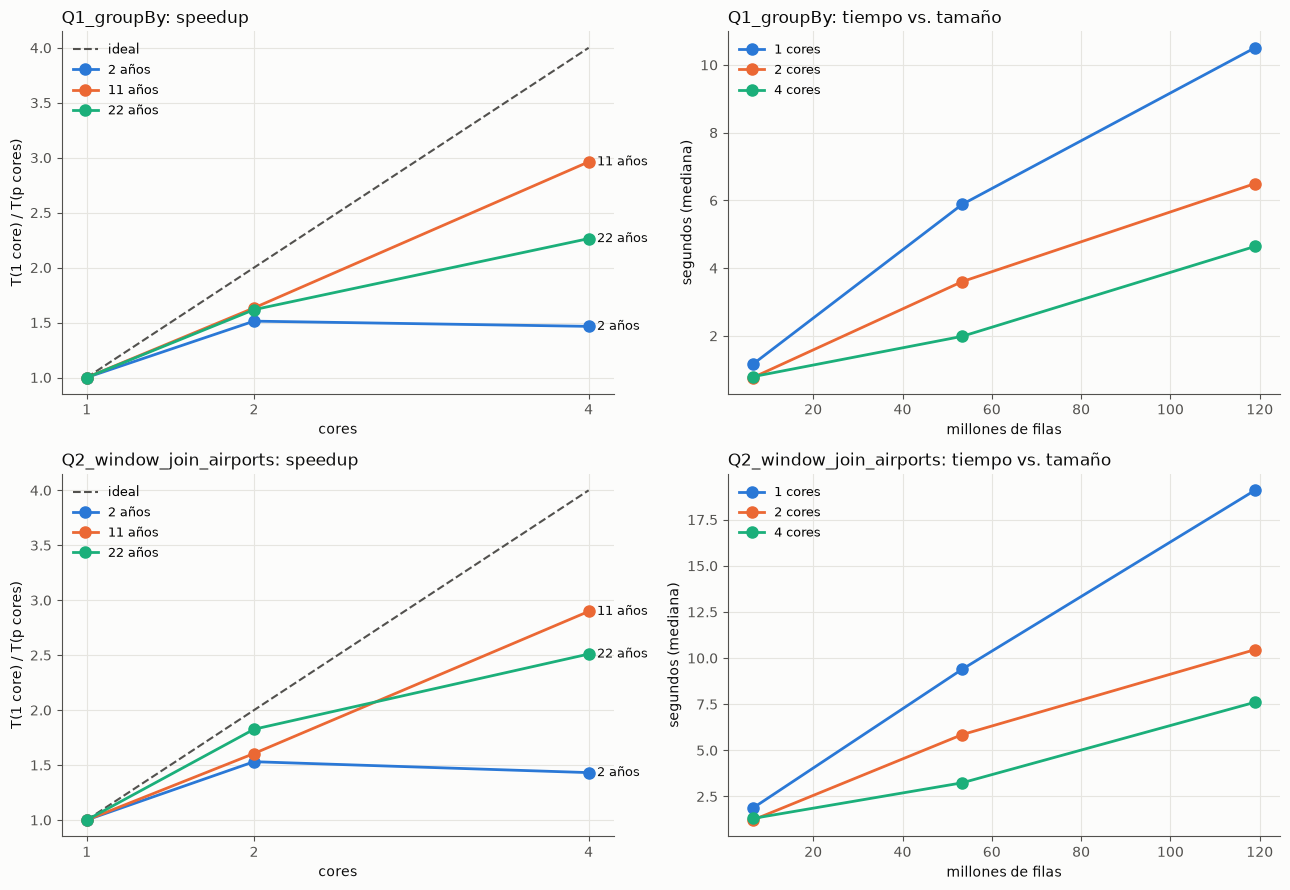

In [13]:
# 6.5 Gráficos para el informe
SURF, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # orden fijo de colores
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

fig, axes = plt.subplots(2, 2, figsize=(13, 9), facecolor=SURF)
for fila, consulta in enumerate(CONSULTAS):
    d = escalado[escalado.consulta == consulta]

    ax = axes[fila, 0]; ax.set_facecolor(SURF)
    ax.plot(CORES, CORES, ls="--", lw=1.5, color=MUTED, label="ideal")
    for color, (k, g) in zip(SERIES, d.groupby("anios")):
        g = g.sort_values("cores")
        ax.plot(g.cores, g.speedup, marker="o", ms=8, lw=2, color=color, label=f"{k} años")
        ax.annotate(f"{k} años", (g.cores.iloc[-1], g.speedup.iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.set_title(f"{consulta}: speedup", loc="left", color=INK)
    ax.set_xlabel("cores"); ax.set_ylabel("T(1 core) / T(p cores)"); ax.set_xticks(CORES)
    ax.grid(color=GRID, lw=0.8); ax.legend(frameon=False, fontsize=9)

    ax = axes[fila, 1]; ax.set_facecolor(SURF)
    for color, (c, g) in zip(SERIES, d.groupby("cores")):
        g = g.sort_values("filas")
        ax.plot(g.filas / 1e6, g.mediana_s, marker="o", ms=8, lw=2, color=color, label=f"{c} cores")
    ax.set_title(f"{consulta}: tiempo vs. tamaño", loc="left", color=INK)
    ax.set_xlabel("millones de filas"); ax.set_ylabel("segundos (mediana)")
    ax.grid(color=GRID, lw=0.8); ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(EVIDENCE / "escalado.png", dpi=160, bbox_inches="tight", facecolor=SURF)
plt.show()

In [14]:
# 6.6 Volver a la sesión normal (todos los cores del clúster)
spark.stop(); time.sleep(3)
spark = SparkSession.builder.master(CONFIG["spark_master"]).appName("miembro3-mapreduce-reto").getOrCreate()
sc = spark.sparkContext
print("cores:", sc.defaultParallelism)

cores: 2


### 6.7 Guía para analizar el reto en el informe
1. **¿Se cumple la hipótesis 1?** Compara el speedup con 4 cores para el subconjunto más pequeño y para todos los años. Si con pocos años S(4) ≈ 1, el tiempo lo dominan los costes fijos, que no se reparten entre cores.
2. **¿Más datos escalan mejor?** Si S(4) crece con el tamaño, la parte que sí se reparte (leer y agregar bloques) pesa cada vez más que la fija.
3. **¿Q1 o Q2 escala peor?** Q2 tiene más shuffle y una ventana. Durante una ejecución con 4 cores, abre `http://localhost:4040` y haz captura de los stages y del *shuffle read/write*. En `explain()` de Q2 debe salir `BroadcastHashJoin`: el join con `airports` no añade shuffle.
4. **¿Por qué no llega al ideal?** Todo corre en un portátil: los workers comparten disco y CPU, y no hay *data locality* (Tema 5). En un clúster real cada worker leería sus bloques de su propio disco.
5. **Las 3 preguntas del final del Tema 5:** ¿y si los datos fueran 100× más grandes? Con nuestras curvas, estima si bastaría con añadir workers o si el disco compartido sería el cuello de botella.
6. **Limitaciones:** una sola máquina física, solo 3 valores de cores, variación entre repeticiones (incluye el rango de `tiempos`), caché del sistema operativo que favorece las repeticiones.

---
# 7. README e informe
La celda siguiente genera la sección del README de este workstream (`evidence/miembro3/README_seccion_miembro3.md`), con los años y rutas reales.

In [ ]:
readme = f"""
## Datos
- Tabla principal: un CSV por año en `data/` ({ANIOS[0]}–{ANIOS[-1]}, {len(ANIOS)} ficheros; `data/` no se sube a GitHub). Funciona con cualquier conjunto de años.
- Tabla auxiliar: `airports.csv` (unión `Origin`/`Dest` = `iata`).
- Ingesta (idempotente, `-put -f`):
```
docker exec {NN} hdfs dfs -mkdir -p {RAW_FLIGHTS} {RAW_LOOKUP}
docker exec {NN} bash -c 'for f in /data/[0-9][0-9][0-9][0-9].csv; do hdfs dfs -put -f "$f" {RAW_FLIGHTS}/; done'
docker exec {NN} hdfs dfs -put -f /data/airports.csv {RAW_LOOKUP}/
```

## MapReduce (Hadoop Streaming) vs. Spark RDD
Scripts en `mapreduce/` (`mapper.py`, `combiner.py`, `reducer.py`, `run_streaming.sh`): vuelos, retraso medio y % con `ArrDelay > 15` por año y aerolínea.
```
docker compose exec namenode hdfs dfsadmin -safemode wait
docker compose exec namenode bash /opt/mapreduce/run_streaming.sh {RAW_FLIGHTS} {RESULTS}/mr_delay_by_carrier_year yes local
```
- `local`: sin YARN (compose del proyecto). `yarn`: clúster de clase con ResourceManager (ver `http://localhost:8088`).
- El NameNode del compose ya incluye `python3` (3.5) y monta `mapreduce/` en `/opt/mapreduce`.
- Idempotente: borra la salida antes de escribir.
- Versión RDD, validación y comparación: secciones 4–5 del notebook `miembro3_mapreduce_reto.ipynb`.

## Reto (bloque F): escalado
Sección 6 del notebook: Q1 (`groupBy`) y Q2 (ventana + join con `airports`) con 1, 2 y 4 cores y {N_ANIOS} años.
Resultados en `evidence/miembro3/escalado_*`. Ejecutar sin otros trabajos pesados en marcha.
"""
(EVIDENCE / "README_seccion_miembro3.md").write_text(readme.strip() + "\n")
print(readme)

In [ ]:
# 7.1 Checklist de evidencias del workstream 3
CHECKLIST = {
    "Entorno del portátil":                   "entorno.json",
    "Ingesta raw (años + airports)":          "ingesta_raw.json",
    "A · 5V volumen por año":                 "5v_volumen_por_anio.csv",
    "A · 5V veracidad":                       "5v_veracidad.json",
    "A · 5V variedad":                        "5v_variedad.json",
    "A · Diagrama":                           "arquitectura.png",
    "C · Log Streaming 1 año con combiner":   "streaming_sample_comb.log",
    "C · Log Streaming 1 año sin combiner":   "streaming_sample_nocomb.log",
    "C · Log Streaming todos los años":       "streaming_full.log",
    "C · Contadores de Hadoop":               "streaming_contadores.csv",
    "C · Tiempos RDD":                        "rdd_tiempos.json",
    "C · Validación MR = RDD":                "validacion_mr_vs_rdd.json",
    "C · Comparativa tiempo y código":        "comparativa_mr_vs_rdd.csv",
    "F · Mediciones de escalado":             "escalado_mediciones.csv",
    "F · Tabla speedup / eficiencia":         "escalado_tabla.csv",
    "F · Gráficos":                           "escalado.png",
    "README · sección":                       "README_seccion_miembro3.md",
}
estado = pd.DataFrame([{"evidencia": k, "fichero": v, "ok": "✔" if (EVIDENCE / v).exists() else "✘ falta"}
                       for k, v in CHECKLIST.items()])
print("Capturas a mano: Spark UI (4040) durante Q2 · Spark Master (8080) con 2 workers · "
      "NameNode UI (9870) con los DataNodes vivos · YARN (8088) si usáis modo yarn")
estado

### 7.2 Estructura del informe (10–14 páginas)

| § | Contenido | Págs. | Quién |
|---|---|---|---|
| 1 | Introducción, dataset (vuelos por año + `airports.csv`) y caso de uso | 1 | Odei (§1, §3.1) |
| 2 | Bloque A: 5V, Data Lake vs. DW, Lambda vs. Kappa, diagrama, entorno Docker | 2 | Odei + Carlos |
| 3 | Bloque B: zonas HDFS, `hdfs fsck`, CSV vs. Parquet | 1,5 | Carlos / Felipe |
| 4 | Bloque C: Streaming vs. RDD, contadores, map-shuffle-reduce | 2 | Odei (§4–5) |
| 5 | Bloque D: ETL, 3 preguntas, `explain()`, optimización | 2,5 | Felipe |
| 6 | Bloque E: pipeline, config, idempotencia, calidad, MLlib | 1,5 | Carlos / Felipe |
| 7 | Bloque F: escalado | 1,5 | Odei (§6) |
| 8 | Limitaciones y registro de decisiones | 1 | Todos |

**Limitaciones de este workstream (§8):**
- Sin YARN en el compose del proyecto: Hadoop Streaming corre en modo `local` dentro del NameNode (no se reparte entre máquinas).
- Todo el clúster está en un portátil: sin *data locality* y con disco y CPU compartidos (Tema 5), lo que limita el escalado.
- Máximo de 4 cores en el experimento.
- Python 3.5 instalado a mano en el NameNode.
- Si no se usan todos los años registrados (1987–2008) o falta alguna tabla auxiliar registrada, decirlo y justificarlo.

**Registro de decisiones (este workstream):** años detectados automáticamente · `airports.csv` como tabla auxiliar (broadcast join, `left` para no perder vuelos) · agregación año × aerolínea para MapReduce (cruza con la pregunta 1 y con la variable objetivo) · combiner activado y medido · RDD sobre los mismos CSV raw que MapReduce · reto = escalado (reutiliza las consultas y no necesita más infraestructura) · acción `noop` para no medir la transferencia al driver.